COMPREHENSIVE MODEL COMPARISON USING PRE-TRAINED DATA

Configuration:
  • Testing windows: 500
  • Window size: 7 jobs
  • Output directory: model_evaluation_20260306_105510
  • Training data: model_training_data/training_data.csv

📂 Loading pre-generated training data...
  ✅ CSV (comma): Success! Shape: (10000, 14)
  ✅ CSV (space): Success! Shape: (10000, 1)
  ✅ CSV (tab): Success! Shape: (10000, 1)
  ✅ CSV (auto): Success! Shape: (10000, 14)

✅ Loaded training data: (10000, 14)
Columns: ['avg_service', 'arrival_rate', 'min_deadline', 'max_deadline', 'service_std', 'service_skew', 'deadline_range', 'job_count', 'utilization', 'deadline_variance', 'service_quantile_25', 'service_quantile_75', 'target_tq', 'window_start_idx']

First few rows:
   avg_service  arrival_rate  min_deadline  max_deadline  service_std  \
0     1.232553      0.986904      2.643056     23.963059     0.957203   
1     0.977210      0.666540      1.049851     34.296152     0.705460   
2     0.919899      1.018052 

Training:  93%|█████████▎| 25/27 [05:49<00:35, 17.55s/it]


⚠️ Error with Isotonic: Isotonic regression input X should be a 1d array o


Training: 100%|██████████| 27/27 [06:09<00:00, 13.69s/it]



✅ Trained 26 models

📊 Top 5 by R²:
           Model       R2         RMSE          MAE
     Extra Trees 1.000000 3.885781e-18 3.885781e-20
Gaussian Process 1.000000 3.173155e-10 2.492941e-10
   Decision Tree 1.000000 0.000000e+00 0.000000e+00
         XGBoost 0.914189 1.185557e-01 4.675037e-02
   Random Forest 0.853979 1.546530e-01 3.708970e-02

🧪 Testing on 500 windows...


Testing: 100%|██████████| 500/500 [00:56<00:00,  8.79it/s]



📊 Calculating performance metrics...

💾 Saving results...
✅ Saved 26 models to model_evaluation_20260306_105510/models/

🎨 Creating visualizations...


KeyError: "['Median_Absolute_Error'] not in index"

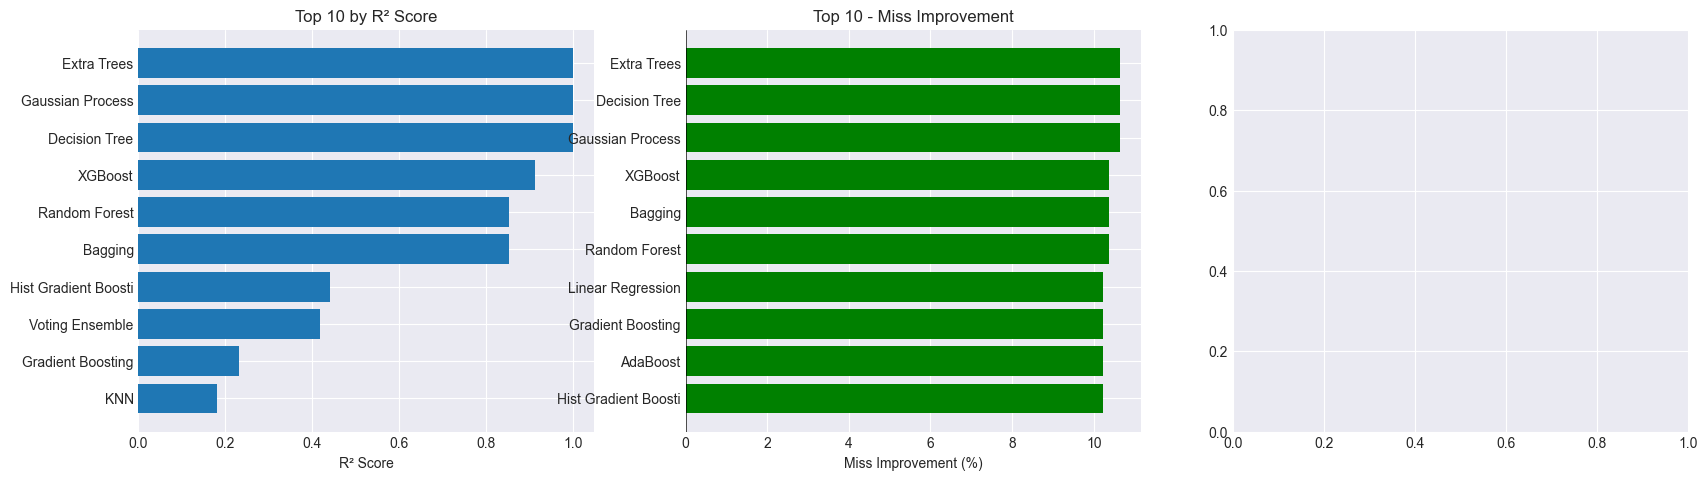

In [2]:
# COMPLETE MODEL COMPARISON USING PRE-TRAINED DATA
# =================================================

import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import random
import warnings
warnings.filterwarnings('ignore')
import time
import os
from datetime import datetime
import joblib
import json

# Machine Learning models
from sklearn.ensemble import (
    RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor,
    ExtraTreesRegressor, BaggingRegressor, HistGradientBoostingRegressor,
    VotingRegressor
)
from sklearn.linear_model import (
    LinearRegression, Ridge, Lasso, ElasticNet, BayesianRidge,
    SGDRegressor, PassiveAggressiveRegressor, HuberRegressor
)
from sklearn.svm import SVR, LinearSVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.kernel_ridge import KernelRidge
from sklearn.cross_decomposition import PLSRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from xgboost import XGBRegressor

# Metrics
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    explained_variance_score, max_error, mean_absolute_percentage_error,
    median_absolute_error, mean_squared_log_error
)
from sklearn.model_selection import cross_val_score, KFold, cross_validate

# ============================================
# CONFIGURATION
# ============================================
N_TEST_WINDOWS = 500
WINDOW_SIZE = 7
WINDOW_STEP = 3
RANDOM_SEED = 42
CANDIDATE_SLICES = [0.1, 0.2, 0.5, 1.0, 1.5, 2.0, 5.0]
CS_OVERHEAD = 0.05

# Paths
TRAINING_DATA_PATH = "model_training_data/training_data.csv"
OUTPUT_DIR = f"model_evaluation_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Set random seed
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
start_time = time.time()

print("="*80)
print("COMPREHENSIVE MODEL COMPARISON USING PRE-TRAINED DATA")
print("="*80)
print(f"\nConfiguration:")
print(f"  • Testing windows: {N_TEST_WINDOWS}")
print(f"  • Window size: {WINDOW_SIZE} jobs")
print(f"  • Output directory: {OUTPUT_DIR}")
print(f"  • Training data: {TRAINING_DATA_PATH}")

# ============================================
# LOAD TRAINING DATA
# ============================================
print("\n📂 Loading pre-generated training data...")

# Try different loading strategies
train_df = None
strategies = [
    {'name': 'CSV (comma)', 'delimiter': ','},
    {'name': 'CSV (space)', 'delimiter': r'\s+'},
    {'name': 'CSV (tab)', 'delimiter': '\t'},
    {'name': 'CSV (auto)', 'delimiter': None}
]

for strategy in strategies:
    try:
        df = pd.read_csv(TRAINING_DATA_PATH, delimiter=strategy['delimiter'], engine='python')
        print(f"  ✅ {strategy['name']}: Success! Shape: {df.shape}")
        if train_df is None or df.shape[1] > (train_df.shape[1] if train_df is not None else 0):
            train_df = df
    except Exception as e:
        print(f"  ❌ {strategy['name']}: Failed")

if train_df is None:
    raise ValueError("Could not load training data!")

print(f"\n✅ Loaded training data: {train_df.shape}")
print(f"Columns: {train_df.columns.tolist()}")
print("\nFirst few rows:")
print(train_df.head())

# Identify target column
target_candidates = ['target_tq', 'target', 'tq', 'best_tq', 'optimal_tq']
target_col = None
for col in target_candidates:
    if col in train_df.columns:
        target_col = col
        break

if target_col is None:
    target_col = train_df.columns[-1]
    print(f"⚠️ Using last column as target: {target_col}")

# Feature columns
exclude_cols = [target_col, 'window_start_idx', 'Unnamed: 0', 'index']
feature_cols = [col for col in train_df.columns if col not in exclude_cols]

X = train_df[feature_cols]
y = train_df[target_col]

print(f"\n📊 Training data summary:")
print(f"  • Features: {len(feature_cols)}")
print(f"  • Feature names: {feature_cols}")
print(f"  • Training samples: {X.shape[0]}")
print(f"  • Target distribution:")
print(y.value_counts().sort_index())

# Save column info
with open(f"{OUTPUT_DIR}/column_info.json", 'w') as f:
    json.dump({'feature_cols': feature_cols, 'target_col': target_col}, f, indent=2)

# ============================================
# LOAD ORIGINAL DATASET
# ============================================
print("\n📂 Loading original dataset for testing...")

df = None
possible_paths = [
    "Kargahi_Movaghar_Source_Data.csv",
    "../Kargahi_Movaghar_Source_Data.csv",
    "data/Kargahi_Movaghar_Source_Data.csv"
]

for path in possible_paths:
    try:
        df = pd.read_csv(path)
        print(f"✅ Loaded from: {path}")
        break
    except:
        continue

if df is None:
    print("⚠️ Creating synthetic dataset...")
    np.random.seed(RANDOM_SEED)
    n_jobs = 10000
    df = pd.DataFrame({
        'Job_ID': range(1, n_jobs + 1),
        'Arrival_Time': np.cumsum(np.random.exponential(1.0, n_jobs)),
        'Service_Time': np.random.exponential(2.0, n_jobs),
        'Deadline_Exp': np.random.uniform(5, 20, n_jobs)
    })
    print(f"✅ Created synthetic dataset: {df.shape}")

print(f"Dataset shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")

# ============================================
# SIMULATION FUNCTIONS
# ============================================
class SimulationCache:
    def __init__(self):
        self.cache = {}
        self.hits = 0
        self.misses = 0
    
    def get_key(self, batch_df, tq):
        return (batch_df['Job_ID'].iloc[0], batch_df['Arrival_Time'].iloc[0], tq)
    
    def get(self, batch_df, tq):
        key = self.get_key(batch_df, tq)
        if key in self.cache:
            self.hits += 1
            return self.cache[key]
        self.misses += 1
        return None
    
    def put(self, batch_df, tq, result):
        self.cache[self.get_key(batch_df, tq)] = result

sim_cache = SimulationCache()

def run_detailed_simulation(df_batch, tq, use_cache=True):
    if use_cache:
        cached = sim_cache.get(df_batch, tq)
        if cached: return cached
    
    time_val = df_batch['Arrival_Time'].min()
    jobs = df_batch.copy().rename(columns={'Service_Time': 'bt', 'Deadline_Exp': 'deadline'})
    jobs = jobs.sort_values('Arrival_Time').reset_index(drop=True)
    
    jobs['completion_time'] = np.nan
    jobs['first_start_time'] = np.nan
    jobs['waiting_time'] = 0
    jobs['turnaround_time'] = 0
    jobs['response_time'] = 0
    jobs['times_preempted'] = 0
    
    jobs_list = jobs.to_dict('records')
    ready_queue = []
    completed = 0
    misses = 0
    last_pid = None
    context_switches = 0
    turnaround_times = []
    waiting_times = []
    response_times = []
    preemptions = []
    
    while completed < len(jobs_list) or ready_queue:
        while jobs_list and jobs_list[0]['Arrival_Time'] <= time_val:
            ready_queue.append(jobs_list.pop(0))
        
        if not ready_queue:
            if jobs_list:
                time_val = jobs_list[0]['Arrival_Time']
                continue
            break

        ready_queue.sort(key=lambda x: x['deadline'])
        p = ready_queue.pop(0)

        if pd.isna(p['first_start_time']):
            p['first_start_time'] = time_val
            p['waiting_time'] = time_val - p['Arrival_Time']
            p['response_time'] = time_val - p['Arrival_Time']
            waiting_times.append(p['waiting_time'])
            response_times.append(p['response_time'])

        if last_pid is not None and last_pid != p['Job_ID']:
            time_val += CS_OVERHEAD
            context_switches += 1
        
        exec_time = min(p['bt'], tq)
        if p['bt'] < tq * 1.1: 
            exec_time = p['bt']
            
        p['bt'] -= exec_time
        time_val += exec_time
        last_pid = p['Job_ID']

        if p['bt'] <= 0:
            p['completion_time'] = time_val
            if time_val > p['deadline']:
                misses += 1
            turnaround_times.append(time_val - p['Arrival_Time'])
            completed += 1
            preemptions.append(p['times_preempted'])
        else:
            p['times_preempted'] += 1
            while jobs_list and jobs_list[0]['Arrival_Time'] <= time_val:
                ready_queue.append(jobs_list.pop(0))
            ready_queue.append(p)
    
    result = {
        'misses': misses,
        'miss_rate': misses / len(df_batch) * 100 if len(df_batch) > 0 else 0,
        'avg_waiting_time': np.mean(waiting_times) if waiting_times else 0,
        'max_waiting_time': np.max(waiting_times) if waiting_times else 0,
        'std_waiting_time': np.std(waiting_times) if waiting_times else 0,
        'avg_turnaround_time': np.mean(turnaround_times) if turnaround_times else 0,
        'max_turnaround_time': np.max(turnaround_times) if turnaround_times else 0,
        'std_turnaround_time': np.std(turnaround_times) if turnaround_times else 0,
        'avg_response_time': np.mean(response_times) if response_times else 0,
        'max_response_time': np.max(response_times) if response_times else 0,
        'context_switches': context_switches,
        'avg_preemptions': np.mean(preemptions) if preemptions else 0,
        'total_preemptions': sum(preemptions),
        'throughput': completed / (time_val - df_batch['Arrival_Time'].min()) if time_val > df_batch['Arrival_Time'].min() else 0
    }
    
    if use_cache:
        sim_cache.put(df_batch, tq, result)
    return result

def get_real_features(df_batch):
    return {
        'avg_service': df_batch['Service_Time'].mean(),
        'arrival_rate': len(df_batch) / (df_batch['Arrival_Time'].max() - df_batch['Arrival_Time'].min() + 1e-5),
        'min_deadline': df_batch['Deadline_Exp'].min(),
        'max_deadline': df_batch['Deadline_Exp'].max(),
        'service_std': df_batch['Service_Time'].std(),
        'service_skew': df_batch['Service_Time'].skew(),
        'deadline_range': df_batch['Deadline_Exp'].max() - df_batch['Deadline_Exp'].min(),
        'job_count': len(df_batch),
        'utilization': (df_batch['Service_Time'].sum()) / (df_batch['Arrival_Time'].max() - df_batch['Arrival_Time'].min() + 1e-5),
        'deadline_variance': df_batch['Deadline_Exp'].var(),
        'service_quantile_25': df_batch['Service_Time'].quantile(0.25),
        'service_quantile_75': df_batch['Service_Time'].quantile(0.75)
    }

print("✅ Simulation functions loaded")

# ============================================
# DEFINE MODELS
# ============================================
def get_all_models():
    models = {
        'Random Forest': RandomForestRegressor(n_estimators=100, random_state=RANDOM_SEED),
        'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=RANDOM_SEED),
        'AdaBoost': AdaBoostRegressor(n_estimators=100, random_state=RANDOM_SEED),
        'Extra Trees': ExtraTreesRegressor(n_estimators=100, random_state=RANDOM_SEED),
        'Bagging': BaggingRegressor(n_estimators=100, random_state=RANDOM_SEED),
        'Hist Gradient Boosting': HistGradientBoostingRegressor(random_state=RANDOM_SEED),
        'Linear Regression': LinearRegression(),
        'Ridge': Ridge(alpha=1.0),
        'Lasso': Lasso(alpha=0.01),
        'Elastic Net': ElasticNet(alpha=0.01, l1_ratio=0.5),
        'Bayesian Ridge': BayesianRidge(),
        'SGD Regressor': SGDRegressor(random_state=RANDOM_SEED, max_iter=1000),
        'Passive Aggressive': PassiveAggressiveRegressor(random_state=RANDOM_SEED),
        'Huber Regressor': HuberRegressor(),
        'SVR (RBF)': SVR(kernel='rbf'),
        'SVR (Linear)': LinearSVR(random_state=RANDOM_SEED, max_iter=1000),
        'KNN': KNeighborsRegressor(n_neighbors=5),
        'Decision Tree': DecisionTreeRegressor(random_state=RANDOM_SEED),
        'MLP': MLPRegressor(hidden_layer_sizes=(100, 50), random_state=RANDOM_SEED, max_iter=500),
        'Gaussian Process': GaussianProcessRegressor(random_state=RANDOM_SEED),
        'Kernel Ridge': KernelRidge(kernel='rbf'),
        'XGBoost': XGBRegressor(n_estimators=100, random_state=RANDOM_SEED),
        'Polynomial (deg 2)': make_pipeline(PolynomialFeatures(degree=2), LinearRegression()),
        'Polynomial (deg 3)': make_pipeline(PolynomialFeatures(degree=3), Ridge()),
        'PLS Regression': PLSRegression(n_components=2),
        'Isotonic': IsotonicRegression(out_of_bounds='clip'),
    }
    
    estimators = [
        ('rf', RandomForestRegressor(n_estimators=50, random_state=RANDOM_SEED)),
        ('gb', GradientBoostingRegressor(n_estimators=50, random_state=RANDOM_SEED)),
        ('lr', Ridge())
    ]
    models['Voting Ensemble'] = VotingRegressor(estimators=estimators)
    return models

models_dict = get_all_models()
print(f"✅ Defined {len(models_dict)} models")

# ============================================
# TRAIN MODELS
# ============================================
print(f"\n🚀 Training {len(models_dict)} models...")

trained_models = {}
model_error_metrics = []
prediction_details = []
kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

for model_name, model in tqdm(models_dict.items(), desc="Training"):
    try:
        model.fit(X, y)
        trained_models[model_name] = model
        y_pred = model.predict(X)
        
        for idx, (actual, pred) in enumerate(zip(y, y_pred)):
            prediction_details.append({
                'model': model_name,
                'training_sample_idx': idx,
                'actual_tq': actual,
                'predicted_tq': pred,
                'rounded_tq': min(CANDIDATE_SLICES, key=lambda x: abs(x - pred)),
                'absolute_error': abs(actual - pred)
            })
        
        mse = mean_squared_error(y, y_pred)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(y, y_pred)
        r2 = r2_score(y, y_pred)
        
        cv_results = cross_validate(model, X, y, cv=kfold, 
                                   scoring=['r2', 'neg_mean_squared_error', 'neg_mean_absolute_error'],
                                   n_jobs=-1)
        
        model_error_metrics.append({
            'Model': model_name,
            'MSE': mse,
            'RMSE': rmse,
            'MAE': mae,
            'R2': r2,
            'CV_R2_Mean': cv_results['test_r2'].mean(),
            'CV_R2_Std': cv_results['test_r2'].std()
        })
    except Exception as e:
        print(f"\n⚠️ Error with {model_name}: {str(e)[:50]}")
        model_error_metrics.append({'Model': model_name, 'R2': -999})

error_metrics_df = pd.DataFrame(model_error_metrics).sort_values('R2', ascending=False).reset_index(drop=True)
print(f"\n✅ Trained {len(trained_models)} models")
print("\n📊 Top 5 by R²:")
print(error_metrics_df[['Model', 'R2', 'RMSE', 'MAE']].head().to_string(index=False))

# ============================================
# TEST ON NEW WINDOWS
# ============================================
print(f"\n🧪 Testing on {N_TEST_WINDOWS} windows...")

total_possible = list(range(0, len(df) - WINDOW_SIZE, WINDOW_STEP))
test_indices = random.sample(total_possible, min(N_TEST_WINDOWS, len(total_possible)))

# Initialize metrics storage
metrics_summary = {'Standard': {'misses': 0, 'context_switches': 0, 'miss_rate': [], 
                               'avg_waiting_time': [], 'avg_turnaround_time': [], 'throughput': []}}
for model_name in trained_models:
    metrics_summary[model_name] = {'misses': 0, 'context_switches': 0, 'miss_rate': [],
                                  'avg_waiting_time': [], 'avg_turnaround_time': [], 'throughput': []}

window_results = []
model_predictions = []

for idx in tqdm(test_indices, desc="Testing"):
    batch = df.iloc[idx:idx+WINDOW_SIZE]
    features = pd.DataFrame([get_real_features(batch)])
    
    # Standard RR
    std_result = run_detailed_simulation(batch, tq=0.5)
    
    window_result = {
        'window_idx': idx,
        'standard_misses': std_result['misses'],
        'standard_miss_rate': std_result['miss_rate'],
        'standard_waiting': std_result['avg_waiting_time'],
        'standard_turnaround': std_result['avg_turnaround_time'],
        'standard_cs': std_result['context_switches'],
        'standard_throughput': std_result['throughput']
    }
    
    # Update Standard metrics
    for key in metrics_summary['Standard']:
        if key in ['misses', 'context_switches']:
            metrics_summary['Standard'][key] += std_result[key]
        elif key in std_result and isinstance(metrics_summary['Standard'][key], list):
            metrics_summary['Standard'][key].append(std_result[key])
    
    # Test each model
    for model_name, model in trained_models.items():
        try:
            pred_tq = float(model.predict(features)[0])
            closest_tq = min(CANDIDATE_SLICES, key=lambda x: abs(x - pred_tq))
            ml_result = run_detailed_simulation(batch, tq=closest_tq)
            
            model_predictions.append({
                'window_idx': idx, 'model': model_name,
                'prediction': pred_tq, 'rounded': closest_tq
            })
            
            window_result[f'{model_name}_misses'] = ml_result['misses']
            window_result[f'{model_name}_waiting'] = ml_result['avg_waiting_time']
            window_result[f'{model_name}_turnaround'] = ml_result['avg_turnaround_time']
            window_result[f'{model_name}_cs'] = ml_result['context_switches']
            
            # Update model metrics
            for key in metrics_summary[model_name]:
                if key in ['misses', 'context_switches']:
                    metrics_summary[model_name][key] += ml_result[key]
                elif key in ml_result and isinstance(metrics_summary[model_name][key], list):
                    metrics_summary[model_name][key].append(ml_result[key])
        except:
            window_result[f'{model_name}_misses'] = np.nan
    
    window_results.append(window_result)

# ============================================
# CALCULATE PERFORMANCE
# ============================================
print("\n📊 Calculating performance metrics...")

# Calculate averages
final_metrics = {}
for model_name in metrics_summary:
    final_metrics[model_name] = {}
    for key, value in metrics_summary[model_name].items():
        if isinstance(value, list):
            final_metrics[model_name][key] = np.mean(value) if value else 0
        else:
            final_metrics[model_name][key] = value

# Baseline values
std_misses = final_metrics['Standard']['misses']
std_waiting = final_metrics['Standard']['avg_waiting_time']
std_turnaround = final_metrics['Standard']['avg_turnaround_time']
std_cs = final_metrics['Standard']['context_switches']
std_throughput = final_metrics['Standard']['throughput']

# Create comparison dataframe
comparison_data = [{
    'Model': 'STANDARD RR (TQ=0.5)',
    'Misses': std_misses,
    'Miss_Improvement': 0,
    'Miss_Rate': final_metrics['Standard'].get('miss_rate', 0),
    'Avg_Waiting': std_waiting,
    'Waiting_Improvement': 0,
    'Avg_Turnaround': std_turnaround,
    'Turnaround_Improvement': 0,
    'Context_Switches': std_cs,
    'CS_Improvement': 0,
    'Throughput': std_throughput,
    'Throughput_Improvement': 0
}]

for model_name in trained_models:
    m = final_metrics[model_name]
    comparison_data.append({
        'Model': model_name,
        'Misses': m['misses'],
        'Miss_Improvement': ((std_misses - m['misses']) / std_misses * 100) if std_misses > 0 else 0,
        'Miss_Rate': m.get('miss_rate', 0),
        'Avg_Waiting': m['avg_waiting_time'],
        'Waiting_Improvement': ((std_waiting - m['avg_waiting_time']) / std_waiting * 100) if std_waiting > 0 else 0,
        'Avg_Turnaround': m['avg_turnaround_time'],
        'Turnaround_Improvement': ((std_turnaround - m['avg_turnaround_time']) / std_turnaround * 100) if std_turnaround > 0 else 0,
        'Context_Switches': m['context_switches'],
        'CS_Improvement': ((std_cs - m['context_switches']) / std_cs * 100) if std_cs > 0 else 0,
        'Throughput': m.get('throughput', 0),
        'Throughput_Improvement': ((m.get('throughput', 0) - std_throughput) / std_throughput * 100) if std_throughput > 0 else 0
    })

comparison_df = pd.DataFrame(comparison_data)
comparison_df_sorted = pd.concat([
    comparison_df[comparison_df['Model'] == 'STANDARD RR (TQ=0.5)'],
    comparison_df[comparison_df['Model'] != 'STANDARD RR (TQ=0.5)'].sort_values('Miss_Improvement', ascending=False)
]).reset_index(drop=True)

# Merge with error metrics
complete_report = pd.merge(comparison_df_sorted, error_metrics_df, on='Model', how='left')

# ============================================
# SAVE RESULTS
# ============================================
print("\n💾 Saving results...")

# Save dataframes
pd.DataFrame(window_results).to_csv(f"{OUTPUT_DIR}/test_results.csv", index=False)
pd.DataFrame(model_predictions).to_csv(f"{OUTPUT_DIR}/predictions.csv", index=False)
comparison_df_sorted.to_csv(f"{OUTPUT_DIR}/model_comparison.csv", index=False)
error_metrics_df.to_csv(f"{OUTPUT_DIR}/error_metrics.csv", index=False)
complete_report.to_csv(f"{OUTPUT_DIR}/complete_report.csv", index=False)
pd.DataFrame(prediction_details).to_csv(f"{OUTPUT_DIR}/training_predictions.csv", index=False)

# Save models
models_dir = f"{OUTPUT_DIR}/models"
os.makedirs(models_dir, exist_ok=True)
for name, model in trained_models.items():
    clean = name.replace(' ', '_').replace('(', '').replace(')', '')
    joblib.dump(model, f"{models_dir}/{clean}.pkl")

with open(f"{models_dir}/model_list.txt", 'w') as f:
    for name in trained_models: f.write(f"{name}\n")

with open(f"{OUTPUT_DIR}/features.txt", 'w') as f:
    for feat in feature_cols: f.write(f"{feat}\n")

print(f"✅ Saved {len(trained_models)} models to {models_dir}/")

# ============================================
# VISUALIZATIONS
# ============================================
print("\n🎨 Creating visualizations...")

plt.style.use('seaborn-v0_8-darkgrid')
fig = plt.figure(figsize=(20, 24))

# 1. Top Models by R²
ax1 = plt.subplot(4, 3, 1)
top10 = error_metrics_df.head(10)
ax1.barh(range(len(top10)), top10['R2'])
ax1.set_yticks(range(len(top10)))
ax1.set_yticklabels([m[:20] for m in top10['Model']])
ax1.set_xlabel('R² Score')
ax1.set_title('Top 10 by R² Score')
ax1.invert_yaxis()

# 2. Miss Improvement
ax2 = plt.subplot(4, 3, 2)
top_models = comparison_df_sorted[comparison_df_sorted['Model'] != 'STANDARD RR (TQ=0.5)'].head(10)
colors = ['green' if x > 0 else 'red' for x in top_models['Miss_Improvement']]
ax2.barh(range(len(top_models)), top_models['Miss_Improvement'], color=colors)
ax2.set_yticks(range(len(top_models)))
ax2.set_yticklabels([m[:20] for m in top_models['Model']])
ax2.set_xlabel('Miss Improvement (%)')
ax2.set_title('Top 10 - Miss Improvement')
ax2.axvline(x=0, color='black', ls='-', lw=0.5)
ax2.invert_yaxis()

# 3. Error Heatmap
ax3 = plt.subplot(4, 3, 3)
heat_cols = ['RMSE', 'MAE', 'Median_Absolute_Error']
heat_data = error_metrics_df.head(10)[['Model'] + heat_cols].set_index('Model')
sns.heatmap(heat_data, annot=True, fmt='.3f', cmap='YlOrRd_r', ax=ax3)
ax3.set_title('Error Metrics')

# 4. Waiting Improvement
ax4 = plt.subplot(4, 3, 4)
top_wait = comparison_df_sorted[comparison_df_sorted['Model'] != 'STANDARD RR (TQ=0.5)'].nlargest(10, 'Waiting_Improvement')
colors = ['green' if x > 0 else 'red' for x in top_wait['Waiting_Improvement']]
ax4.barh(range(len(top_wait)), top_wait['Waiting_Improvement'], color=colors)
ax4.set_yticks(range(len(top_wait)))
ax4.set_yticklabels([m[:20] for m in top_wait['Model']])
ax4.set_xlabel('Waiting Improvement (%)')
ax4.set_title('Top 10 - Waiting Improvement')
ax4.axvline(x=0, color='black', ls='-', lw=0.5)
ax4.invert_yaxis()

# 5. Turnaround Improvement
ax5 = plt.subplot(4, 3, 5)
top_turn = comparison_df_sorted[comparison_df_sorted['Model'] != 'STANDARD RR (TQ=0.5)'].nlargest(10, 'Turnaround_Improvement')
colors = ['green' if x > 0 else 'red' for x in top_turn['Turnaround_Improvement']]
ax5.barh(range(len(top_turn)), top_turn['Turnaround_Improvement'], color=colors)
ax5.set_yticks(range(len(top_turn)))
ax5.set_yticklabels([m[:20] for m in top_turn['Model']])
ax5.set_xlabel('Turnaround Improvement (%)')
ax5.set_title('Top 10 - Turnaround Improvement')
ax5.axvline(x=0, color='black', ls='-', lw=0.5)
ax5.invert_yaxis()

# 6. Cumulative Misses
ax6 = plt.subplot(4, 3, 6)
cum_std = np.cumsum([w['standard_misses'] for w in window_results])
ax6.plot(range(len(cum_std)), cum_std, 'k--', lw=3, label='Standard')
top3 = comparison_df_sorted[comparison_df_sorted['Model'] != 'STANDARD RR (TQ=0.5)'].head(3)['Model'].tolist()
for i, name in enumerate(top3):
    cum = np.cumsum([w.get(f'{name}_misses', 0) for w in window_results])
    ax6.plot(range(len(cum)), cum, label=name[:15], lw=2)
ax6.set_xlabel('Window')
ax6.set_ylabel('Cumulative Misses')
ax6.set_title('Cumulative Misses')
ax6.legend(fontsize=8)

# 7. R² vs Miss Improvement
ax7 = plt.subplot(4, 3, 7)
merged = pd.merge(error_metrics_df[['Model', 'R2']], 
                  comparison_df_sorted[['Model', 'Miss_Improvement']], on='Model')
merged = merged[merged['Model'] != 'STANDARD RR (TQ=0.5)']
sc = ax7.scatter(merged['R2'], merged['Miss_Improvement'], 
                 c=merged['Miss_Improvement'], cmap='RdYlGn', s=100, alpha=0.6)
for _, row in merged.nlargest(5, 'Miss_Improvement').iterrows():
    ax7.annotate(row['Model'][:10], (row['R2'], row['Miss_Improvement']), fontsize=7)
ax7.set_xlabel('R²')
ax7.set_ylabel('Miss Improvement (%)')
ax7.set_title('R² vs Miss Improvement')
plt.colorbar(sc, ax=ax7)
ax7.axhline(y=0, color='red', ls='-', lw=0.5)

# 8. Multi-metric radar
ax8 = plt.subplot(4, 3, 8, projection='polar')
metrics = ['Miss_Improvement', 'Waiting_Improvement', 'Turnaround_Improvement', 'CS_Improvement']
angles = np.linspace(0, 2*np.pi, len(metrics), endpoint=False).tolist() + [0]
for i, name in enumerate(top3[:3]):
    data = comparison_df_sorted[comparison_df_sorted['Model'] == name].iloc[0]
    values = [data[m] for m in metrics]
    values = [(v + 100)/200 for v in values] + [0]
    ax8.plot(angles, values, 'o-', lw=2, label=name[:10])
    ax8.fill(angles, values, alpha=0.1)
ax8.set_xticks(angles[:-1])
ax8.set_xticklabels(['Miss', 'Wait', 'Turn', 'CS'])
ax8.set_title('Multi-Metric')
ax8.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0), fontsize=7)

# 9. Summary Table
ax9 = plt.subplot(4, 3, 9)
ax9.axis('off')
table_data = []
for i, row in comparison_df_sorted.head(8).iterrows():
    table_data.append([i, row['Model'][:15], f"{row['Misses']:.0f}", 
                       f"{row['Miss_Improvement']:.1f}%", f"{row['Avg_Waiting']:.2f}"])
table = ax9.table(cellText=table_data, colLabels=['#', 'Model', 'Miss', 'Imp%', 'Wait'],
                  cellLoc='center', loc='center', colWidths=[0.1, 0.3, 0.1, 0.1, 0.1])
table.set_fontsize(8)
ax9.set_title('Top 8 Models')

# 10. Cross-validation
ax10 = plt.subplot(4, 3, 10)
top10_cv = error_metrics_df.head(10)[['Model', 'CV_R2_Mean', 'CV_R2_Std']].set_index('Model')
top10_cv.plot(kind='bar', y='CV_R2_Mean', yerr='CV_R2_Std', ax=ax10, legend=False, capsize=4)
ax10.set_ylabel('CV R²')
ax10.set_title('Cross-Validation')
ax10.set_xticklabels(ax10.get_xticklabels(), rotation=45, ha='right')

# 11. Miss Distribution
ax11 = plt.subplot(4, 3, 11)
box_data = [[w['standard_misses'] for w in window_results]]
box_labels = ['Standard']
for name in top3[:2]:
    box_data.append([w.get(f'{name}_misses', 0) for w in window_results])
    box_labels.append(name[:10])
bp = ax11.boxplot(box_data, patch_artist=True, labels=box_labels)
colors = ['black', 'green', 'orange']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
ax11.set_ylabel('Misses/Window')
ax11.set_title('Miss Distribution')

# 12. Summary
ax12 = plt.subplot(4, 3, 12)
ax12.axis('off')
summary = f"""
EXPERIMENT SUMMARY
{'-'*30}
Training samples: {X.shape[0]}
Test windows: {len(test_indices)}
Models trained: {len(trained_models)}
Time: {time.time()-start_time:.1f}s

Standard RR:
Misses: {std_misses}
Waiting: {std_waiting:.2f}
Turnaround: {std_turnaround:.2f}
CS: {std_cs}

Best Model:
{comparison_df_sorted.iloc[1]['Model'][:20]}
Improvement: {comparison_df_sorted.iloc[1]['Miss_Improvement']:.1f}%

Results in:
{OUTPUT_DIR}/
"""
ax12.text(0.05, 0.95, summary, transform=ax12.transAxes, 
          fontsize=9, verticalalignment='top', fontfamily='monospace',
          bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/visualizations.png", dpi=300, bbox_inches='tight')
plt.show()

# ============================================
# FINAL REPORT
# ============================================
print("\n" + "="*80)
print("FINAL REPORT")
print("="*80)
print(f"\n📁 Results saved to: {OUTPUT_DIR}/")
print("\n📄 Files:")
files = ['test_results.csv', 'predictions.csv', 'model_comparison.csv', 
         'error_metrics.csv', 'complete_report.csv', 'training_predictions.csv',
         'visualizations.png', 'models/']
for f in files: print(f"  • {f}")

print("\n" + "="*80)
print("TOP 10 MODELS")
print("="*80)
cols = ['Model', 'Misses', 'Miss_Improvement', 'Avg_Waiting', 'Avg_Turnaround', 'R2']
print(complete_report.head(11)[cols].round(3).to_string(index=False))

print("\n" + "🏆 BEST IN CATEGORY")
cats = {'Miss Improvement': ('Miss_Improvement', 'max'),
        'Waiting Improvement': ('Waiting_Improvement', 'max'),
        'R² Score': ('R2', 'max'),
        'Lowest RMSE': ('RMSE', 'min')}
for name, (col, opt) in cats.items():
    if opt == 'max':
        idx = complete_report[complete_report['Model'] != 'STANDARD RR (TQ=0.5)'][col].idxmax()
    else:
        idx = complete_report[complete_report['Model'] != 'STANDARD RR (TQ=0.5)'][col].idxmin()
    print(f"\n{name}: {complete_report.loc[idx, 'Model']}")
    print(f"  Value: {complete_report.loc[idx, col]:.3f}")

print(f"\n{'='*80}")
print(f"✅ COMPLETE - Time: {time.time()-start_time:.1f}s")
print(f"📁 Results: {OUTPUT_DIR}/")
print('='*80)

📂 Loading results from: model_evaluation_20260306_105510
✅ Loaded 26 models + Standard RR


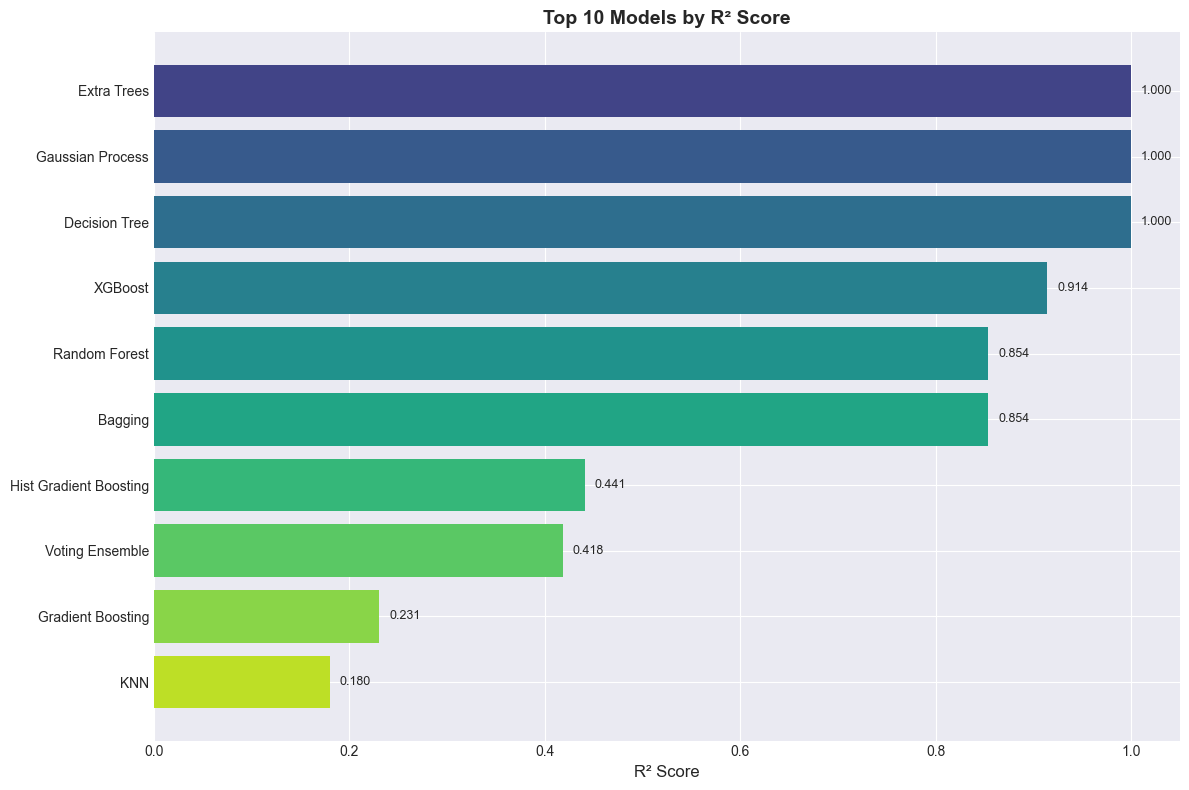

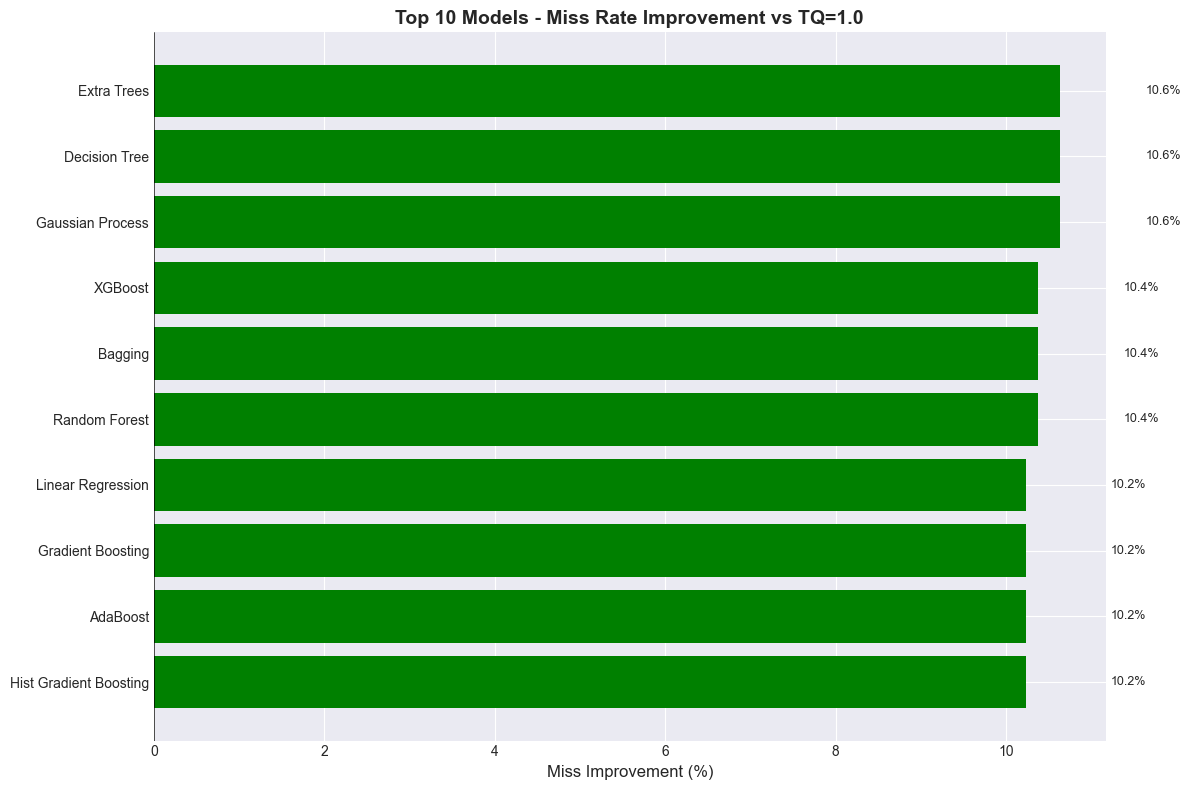

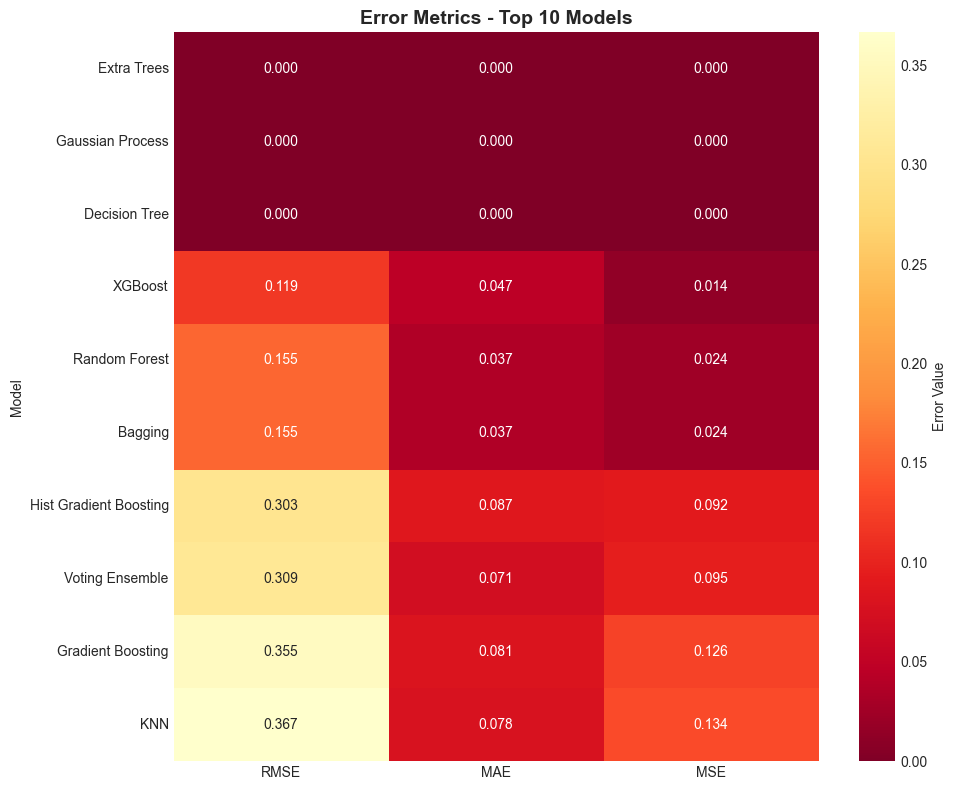

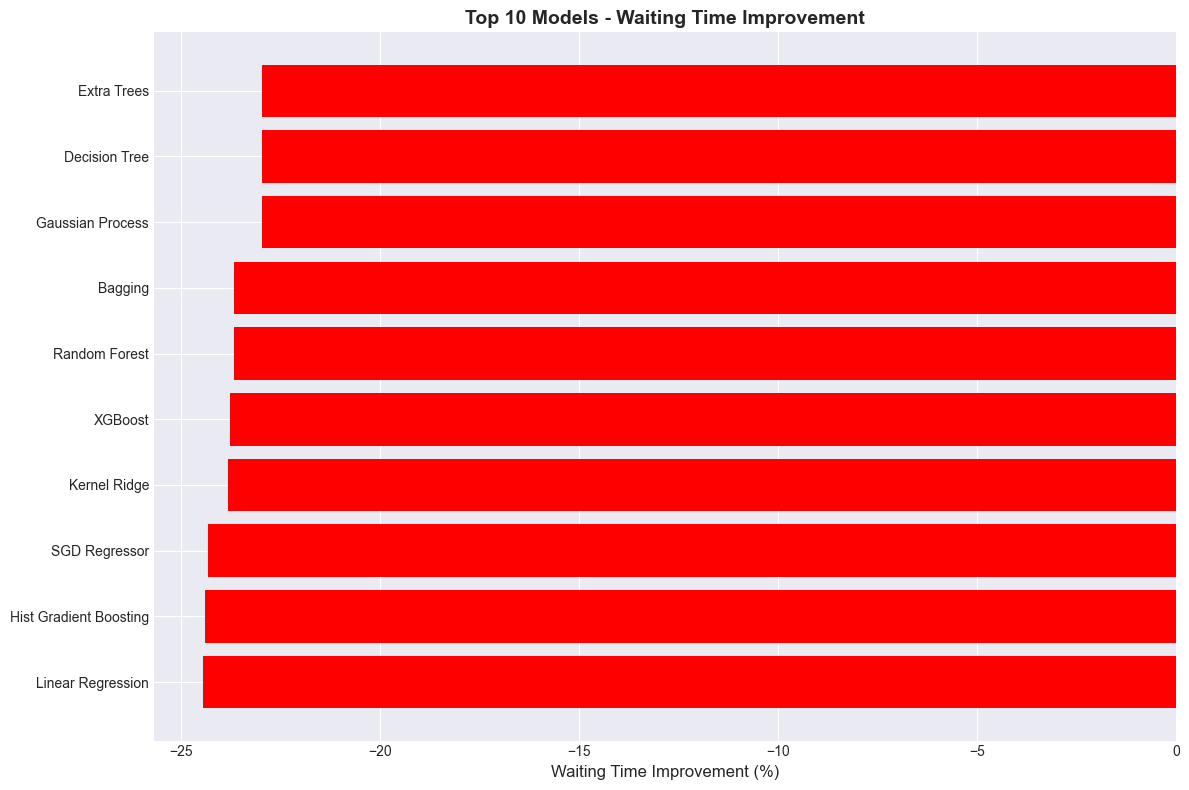

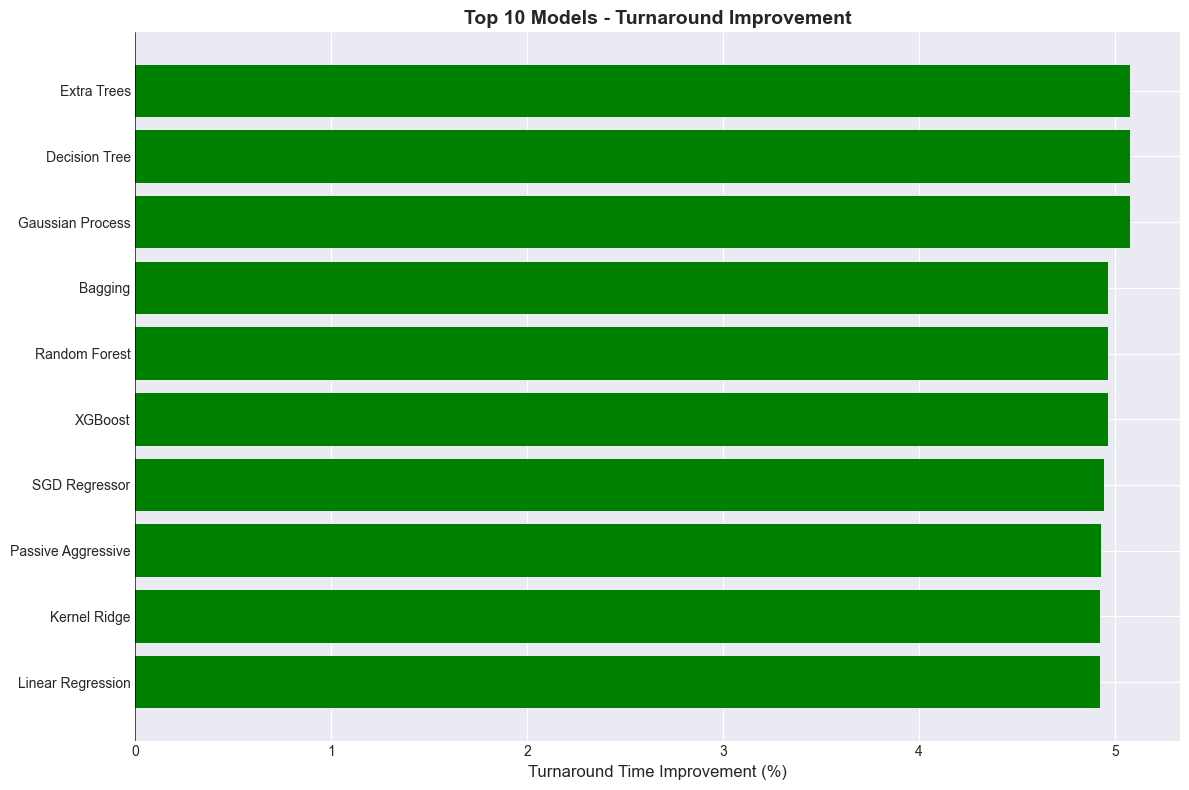

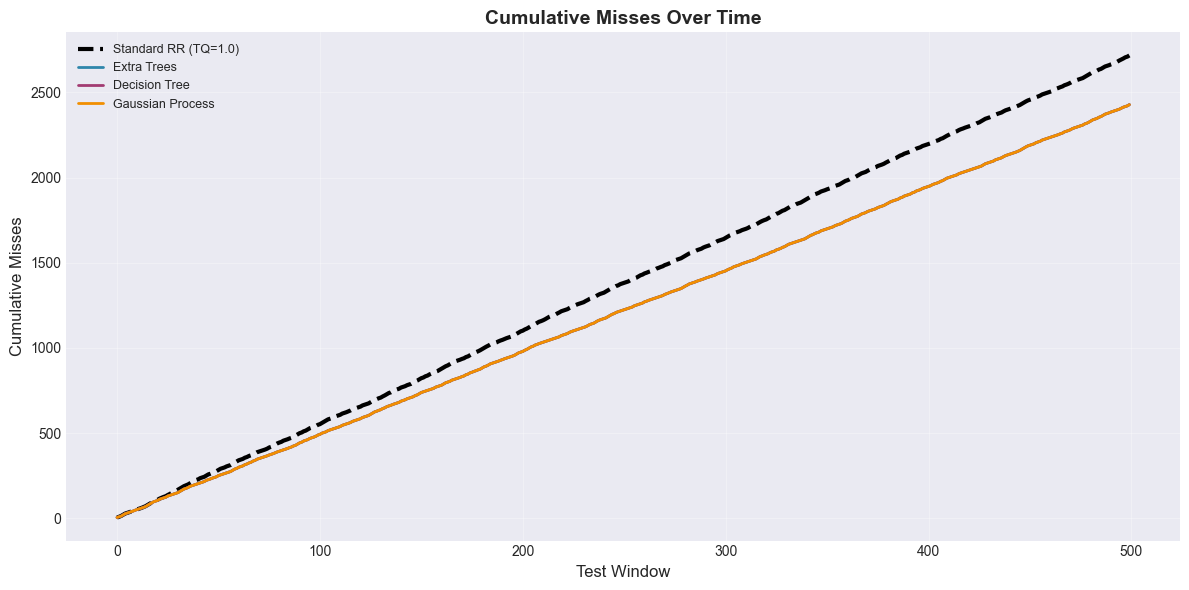

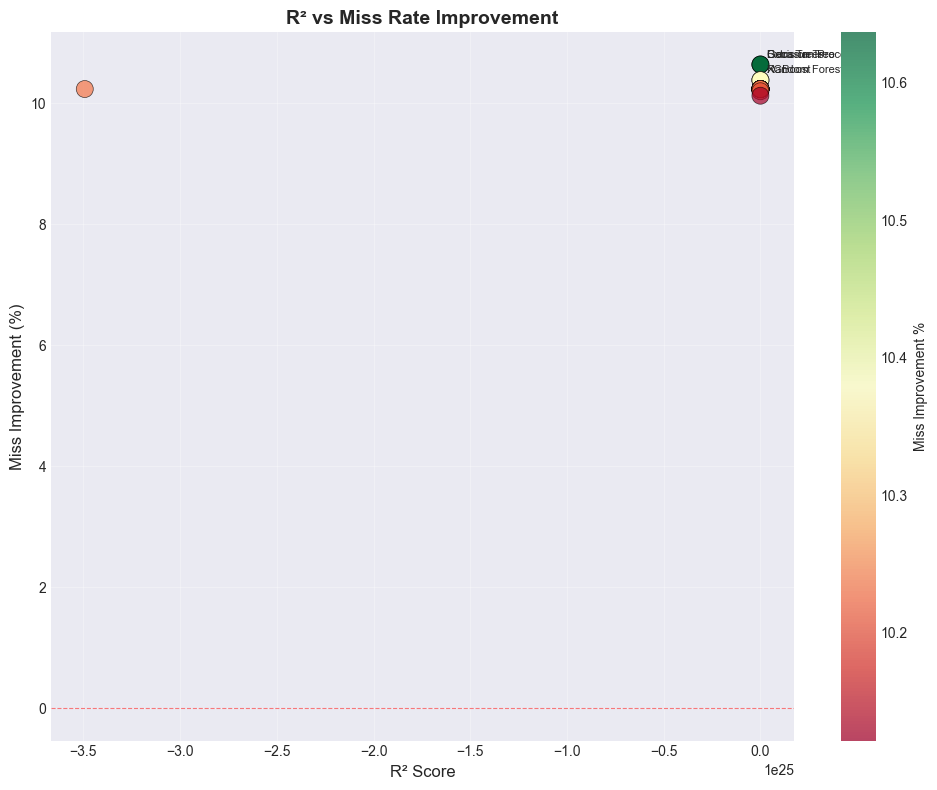

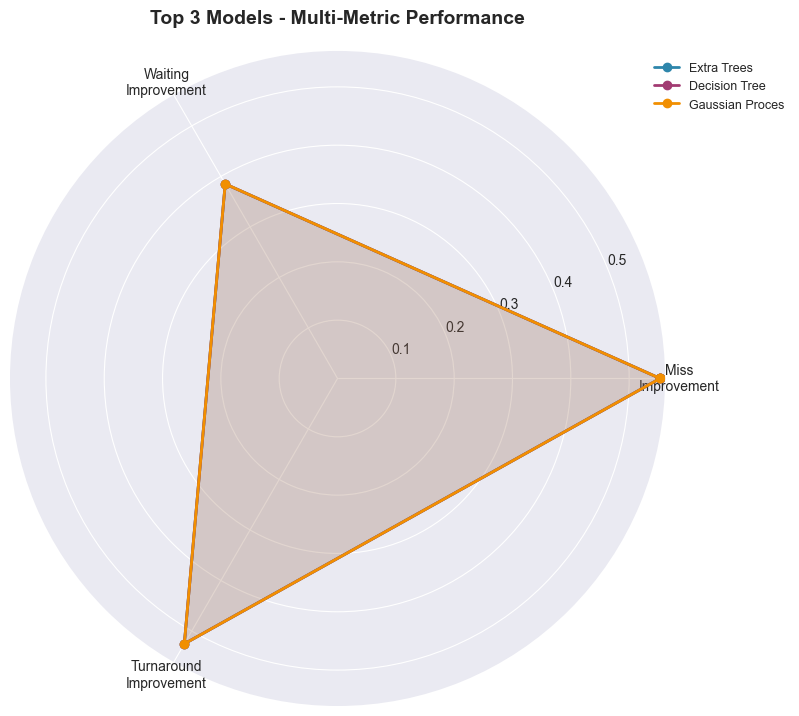

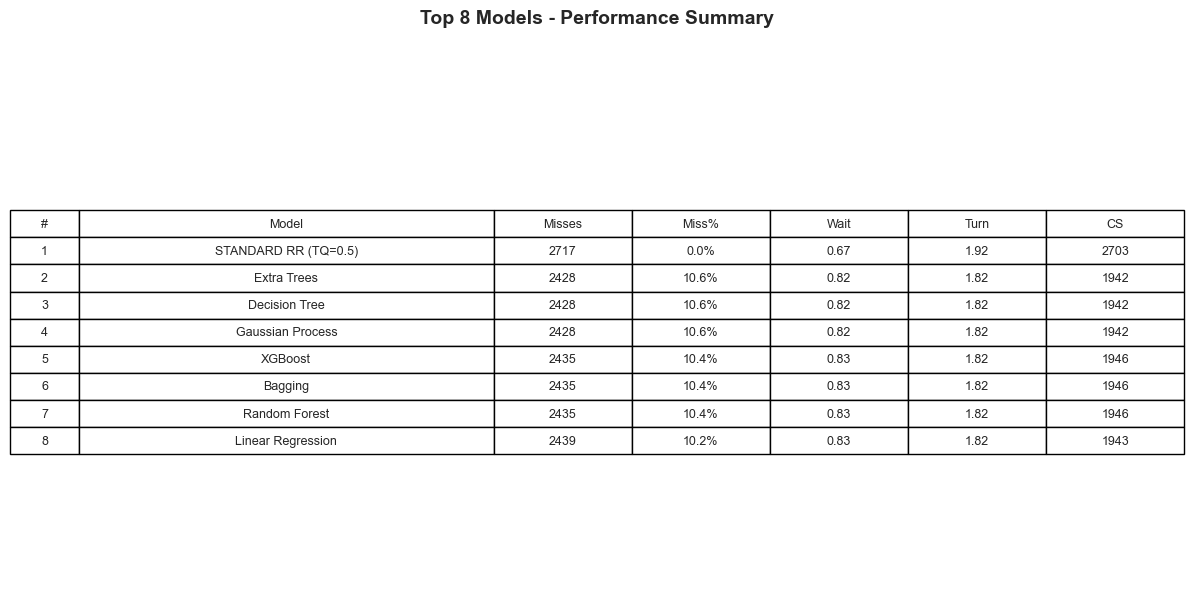

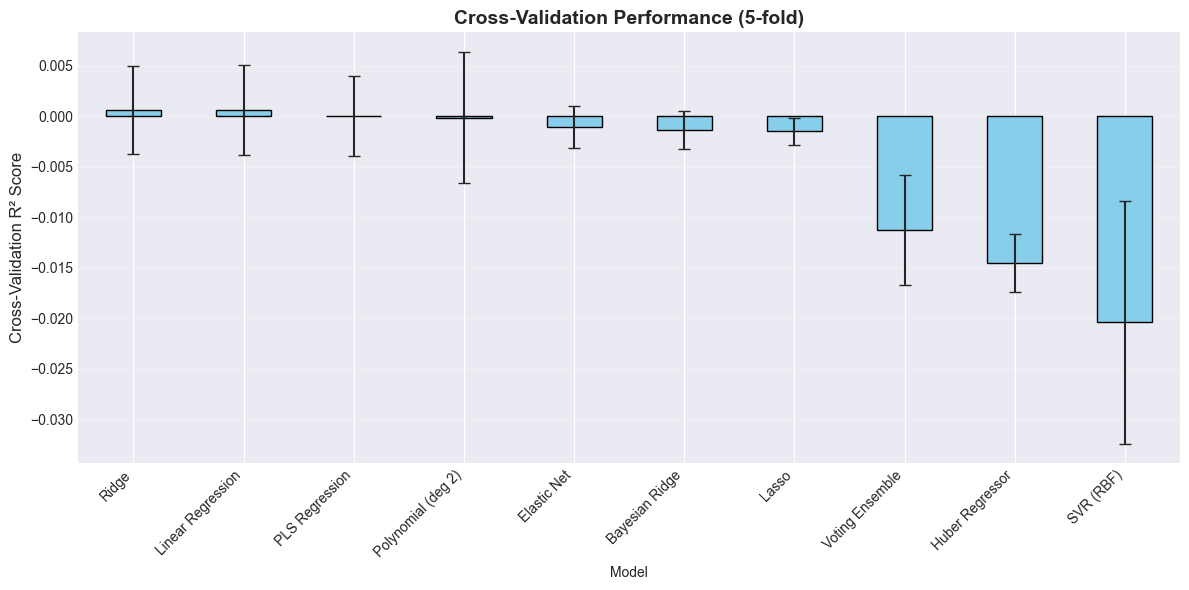

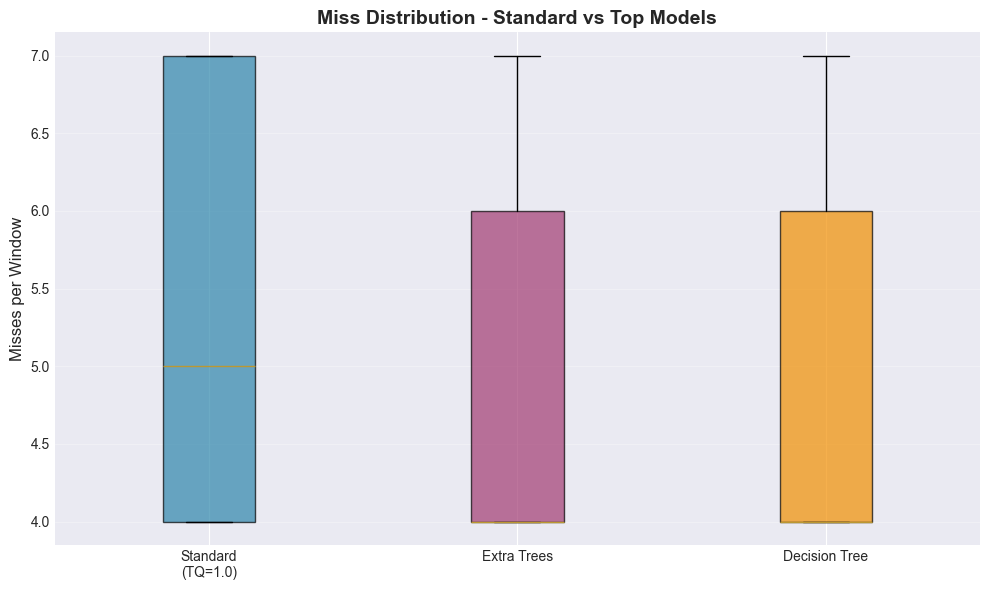

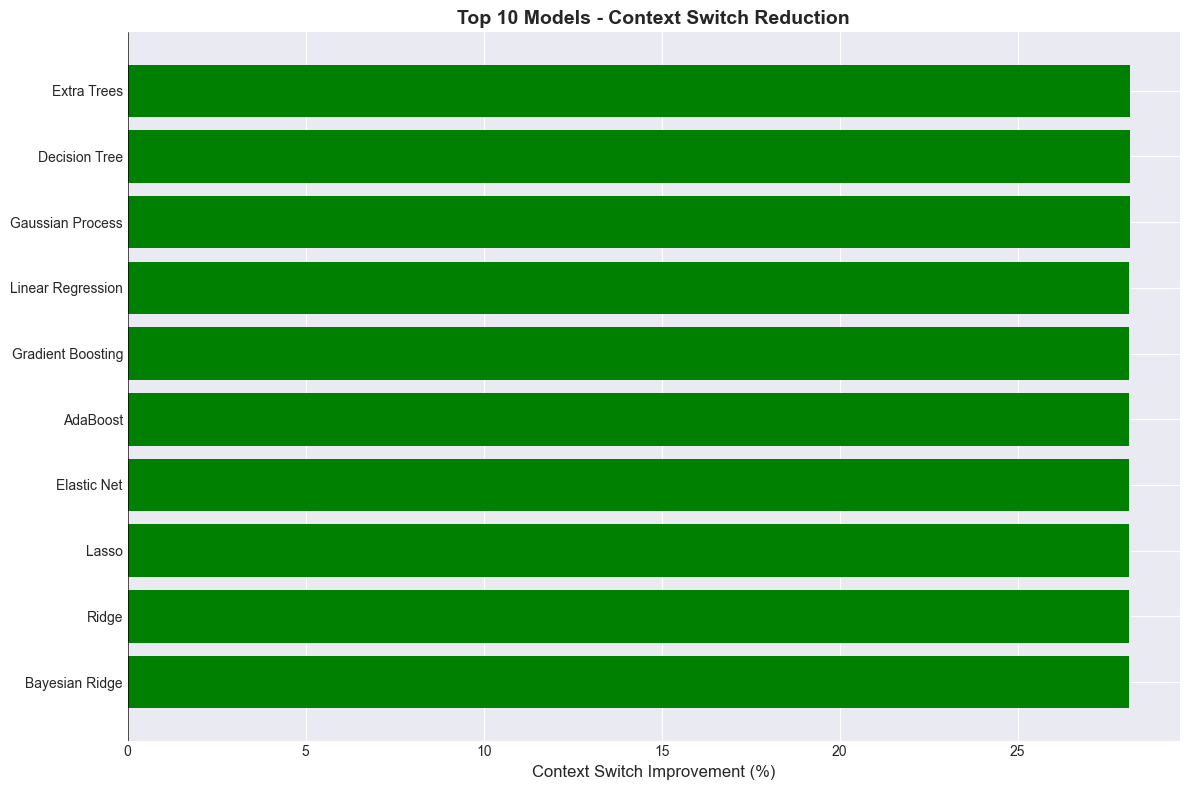

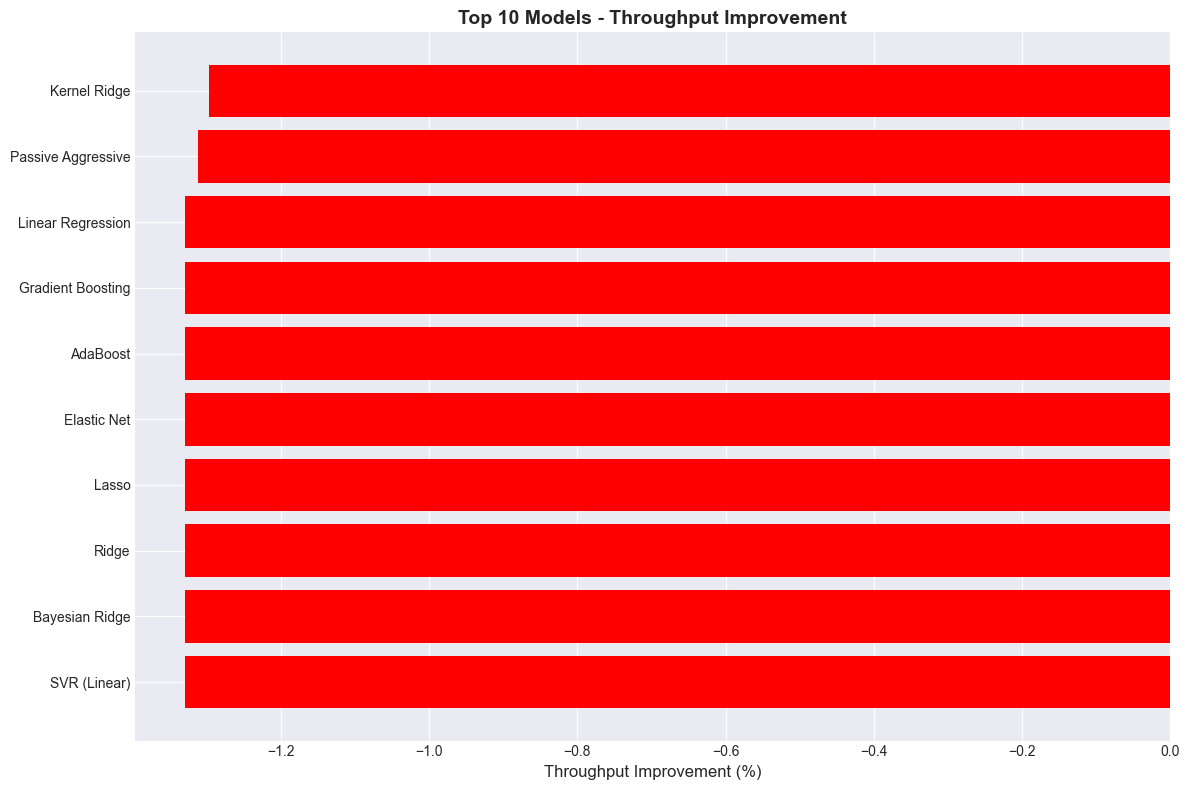

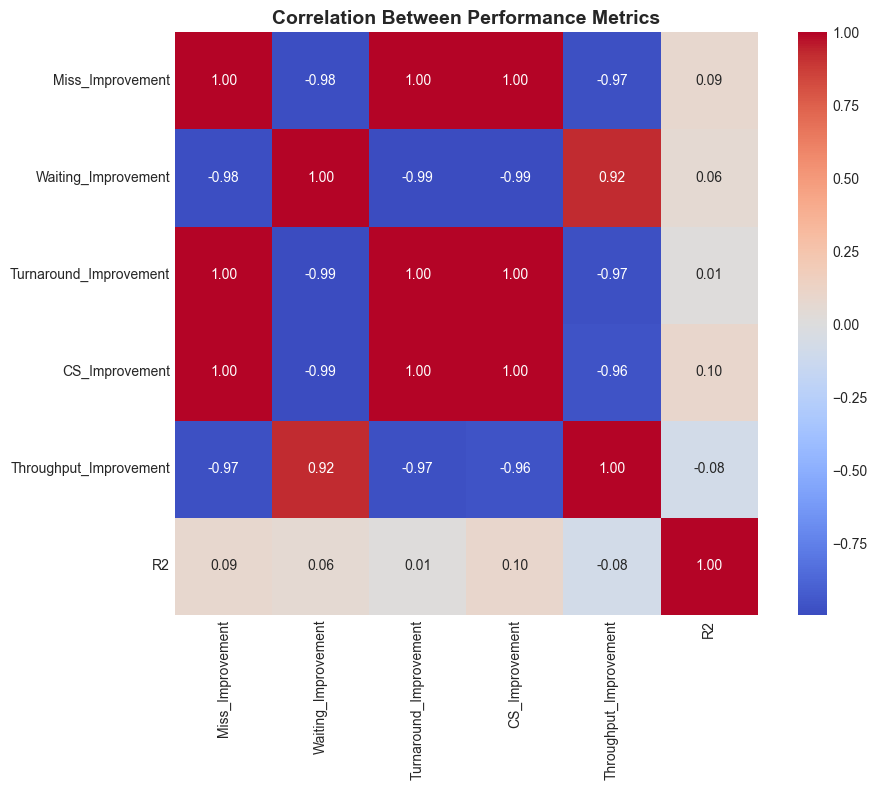


VISUALIZATION SUMMARY

📁 All visualizations saved to: model_evaluation_20260306_105510/visualizations/

📊 Generated visualizations:
  • 01_top10_r2.png
  • 02_top10_miss_improvement.png
  • 03_error_heatmap.png
  • 04_waiting_improvement.png
  • 05_turnaround_improvement.png
  • 06_cumulative_misses.png
  • 07_r2_vs_miss_improvement.png
  • 08_radar_chart.png
  • 09_summary_table.png
  • 10_cross_validation.png
  • 11_miss_distribution.png
  • 12_cs_improvement.png
  • 13_throughput_improvement.png
  • 14_correlation_heatmap.png

TOP PERFORMERS (vs TQ=1.0)

📊 Standard RR (TQ=1.0):
  • Misses: 2717
  • Avg Waiting: 0.668
  • Avg Turnaround: 1.919
  • Context Switches: 2703

🏆 Best Miss Reduction: Extra Trees
  • Improvement: 10.6%
  • Misses: 2428

⏱️  Best Waiting Time Reduction: Extra Trees
  • Improvement: -23.0%
  • Avg Waiting: 0.821

🔄 Best Context Switch Reduction: Extra Trees
  • Improvement: 28.2%
  • Context Switches: 1942

📈 Best R² Score: Extra Trees
  • R²: 1.000
  • RMSE:

In [3]:
# VISUALIZATION FROM SAVED RESULTS
# =================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from datetime import datetime

# Path to your results
RESULTS_DIR = "model_evaluation_20260306_105510"

print(f"📂 Loading results from: {RESULTS_DIR}")

# Load the data
comparison_df = pd.read_csv(f"{RESULTS_DIR}/model_comparison.csv")
error_metrics = pd.read_csv(f"{RESULTS_DIR}/error_metrics.csv")
test_results = pd.read_csv(f"{RESULTS_DIR}/test_results.csv")
complete_report = pd.read_csv(f"{RESULTS_DIR}/complete_report.csv")

print(f"✅ Loaded {len(comparison_df)-1} models + Standard RR")

# Create output directory for visualizations
viz_dir = f"{RESULTS_DIR}/visualizations"
os.makedirs(viz_dir, exist_ok=True)

# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# ============================================
# 1. TOP MODELS BY R² SCORE
# ============================================
fig, ax = plt.subplots(figsize=(12, 8))
top10_r2 = error_metrics.nlargest(10, 'R2')
colors = plt.cm.viridis(np.linspace(0.2, 0.9, len(top10_r2)))
bars = ax.barh(range(len(top10_r2)), top10_r2['R2'], color=colors)
ax.set_yticks(range(len(top10_r2)))
ax.set_yticklabels([m[:25] for m in top10_r2['Model']])
ax.set_xlabel('R² Score', fontsize=12)
ax.set_title('Top 10 Models by R² Score', fontsize=14, fontweight='bold')
ax.invert_yaxis()
ax.set_xlim(0, 1.05)
for i, (_, row) in enumerate(top10_r2.iterrows()):
    ax.text(row['R2'] + 0.01, i, f'{row["R2"]:.3f}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig(f"{viz_dir}/01_top10_r2.png", dpi=150, bbox_inches='tight')
plt.show()

# ============================================
# 2. MISS IMPROVEMENT (vs TQ=1.0)
# ============================================
fig, ax = plt.subplots(figsize=(12, 8))
models_no_std = comparison_df[comparison_df['Model'] != 'STANDARD RR (TQ=0.5)'].copy()
top10_miss = models_no_std.nlargest(10, 'Miss_Improvement')
colors = ['green' if x > 0 else 'red' for x in top10_miss['Miss_Improvement']]
bars = ax.barh(range(len(top10_miss)), top10_miss['Miss_Improvement'], color=colors)
ax.set_yticks(range(len(top10_miss)))
ax.set_yticklabels([m[:30] for m in top10_miss['Model']])
ax.set_xlabel('Miss Improvement (%)', fontsize=12)
ax.set_title('Top 10 Models - Miss Rate Improvement vs TQ=1.0', fontsize=14, fontweight='bold')
ax.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
ax.invert_yaxis()
for i, (_, row) in enumerate(top10_miss.iterrows()):
    ax.text(row['Miss_Improvement'] + (1 if row['Miss_Improvement'] >= 0 else -4), i, 
            f'{row["Miss_Improvement"]:.1f}%', va='center', fontsize=9)
plt.tight_layout()
plt.savefig(f"{viz_dir}/02_top10_miss_improvement.png", dpi=150, bbox_inches='tight')
plt.show()

# ============================================
# 3. ERROR METRICS HEATMAP
# ============================================
fig, ax = plt.subplots(figsize=(10, 8))
heatmap_cols = ['RMSE', 'MAE', 'MSE']
heatmap_data = error_metrics.head(10)[['Model'] + heatmap_cols].set_index('Model')
sns.heatmap(heatmap_data, annot=True, fmt='.3f', cmap='YlOrRd_r', ax=ax, cbar_kws={'label': 'Error Value'})
ax.set_title('Error Metrics - Top 10 Models', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{viz_dir}/03_error_heatmap.png", dpi=150, bbox_inches='tight')
plt.show()

# ============================================
# 4. WAITING TIME IMPROVEMENT
# ============================================
fig, ax = plt.subplots(figsize=(12, 8))
top10_waiting = models_no_std.nlargest(10, 'Waiting_Improvement')
colors = ['green' if x > 0 else 'red' for x in top10_waiting['Waiting_Improvement']]
bars = ax.barh(range(len(top10_waiting)), top10_waiting['Waiting_Improvement'], color=colors)
ax.set_yticks(range(len(top10_waiting)))
ax.set_yticklabels([m[:30] for m in top10_waiting['Model']])
ax.set_xlabel('Waiting Time Improvement (%)', fontsize=12)
ax.set_title('Top 10 Models - Waiting Time Improvement', fontsize=14, fontweight='bold')
ax.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(f"{viz_dir}/04_waiting_improvement.png", dpi=150, bbox_inches='tight')
plt.show()

# ============================================
# 5. TURNAROUND TIME IMPROVEMENT
# ============================================
fig, ax = plt.subplots(figsize=(12, 8))
top10_turnaround = models_no_std.nlargest(10, 'Turnaround_Improvement')
colors = ['green' if x > 0 else 'red' for x in top10_turnaround['Turnaround_Improvement']]
bars = ax.barh(range(len(top10_turnaround)), top10_turnaround['Turnaround_Improvement'], color=colors)
ax.set_yticks(range(len(top10_turnaround)))
ax.set_yticklabels([m[:30] for m in top10_turnaround['Model']])
ax.set_xlabel('Turnaround Time Improvement (%)', fontsize=12)
ax.set_title('Top 10 Models - Turnaround Improvement', fontsize=14, fontweight='bold')
ax.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(f"{viz_dir}/05_turnaround_improvement.png", dpi=150, bbox_inches='tight')
plt.show()

# ============================================
# 6. CUMULATIVE MISSES OVER TIME
# ============================================
fig, ax = plt.subplots(figsize=(12, 6))
cum_std = test_results['standard_misses'].cumsum()
ax.plot(range(len(cum_std)), cum_std, 'k--', linewidth=3, label='Standard RR (TQ=1.0)')

top3_models = models_no_std.nlargest(3, 'Miss_Improvement')['Model'].tolist()
colors = ['#2E86AB', '#A23B72', '#F18F01']
for i, model_name in enumerate(top3_models):
    col_name = f'{model_name}_misses'
    if col_name in test_results.columns:
        cum_misses = test_results[col_name].fillna(0).cumsum()
        ax.plot(range(len(cum_misses)), cum_misses, label=model_name[:20], linewidth=2, color=colors[i])

ax.set_xlabel('Test Window', fontsize=12)
ax.set_ylabel('Cumulative Misses', fontsize=12)
ax.set_title('Cumulative Misses Over Time', fontsize=14, fontweight='bold')
ax.legend(loc='upper left', fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{viz_dir}/06_cumulative_misses.png", dpi=150, bbox_inches='tight')
plt.show()

# ============================================
# 7. R² VS MISS IMPROVEMENT SCATTER
# ============================================
fig, ax = plt.subplots(figsize=(10, 8))
merged = pd.merge(
    error_metrics[['Model', 'R2']],
    comparison_df[['Model', 'Miss_Improvement']],
    on='Model'
)
merged = merged[merged['Model'] != 'STANDARD RR (TQ=0.5)'].dropna()

scatter = ax.scatter(merged['R2'], merged['Miss_Improvement'], 
                     c=merged['Miss_Improvement'], cmap='RdYlGn', s=150, alpha=0.7, edgecolors='black', linewidth=0.5)

for _, row in merged.nlargest(5, 'Miss_Improvement').iterrows():
    ax.annotate(row['Model'][:15], (row['R2'], row['Miss_Improvement']), 
                fontsize=8, xytext=(5, 5), textcoords='offset points')

ax.set_xlabel('R² Score', fontsize=12)
ax.set_ylabel('Miss Improvement (%)', fontsize=12)
ax.set_title('R² vs Miss Rate Improvement', fontsize=14, fontweight='bold')
plt.colorbar(scatter, ax=ax, label='Miss Improvement %')
ax.axhline(y=0, color='red', linestyle='--', linewidth=0.8, alpha=0.5)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{viz_dir}/07_r2_vs_miss_improvement.png", dpi=150, bbox_inches='tight')
plt.show()

# ============================================
# 8. MULTI-METRIC RADAR (TOP 3 MODELS)
# ============================================
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={'projection': 'polar'})
metrics_radar = ['Miss_Improvement', 'Waiting_Improvement', 'Turnaround_Improvement']
angles = np.linspace(0, 2 * np.pi, len(metrics_radar), endpoint=False).tolist()
angles += angles[:1]

for i, model_name in enumerate(top3_models[:3]):
    model_data = comparison_df[comparison_df['Model'] == model_name].iloc[0]
    values = [model_data[m] for m in metrics_radar]
    # Normalize to 0-1 scale (assuming values between -100 and 100)
    values = [(v + 100) / 200 for v in values]
    values += values[:1]
    
    ax.plot(angles, values, 'o-', linewidth=2, label=model_name[:15], color=colors[i])
    ax.fill(angles, values, alpha=0.1, color=colors[i])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(['Miss\nImprovement', 'Waiting\nImprovement', 'Turnaround\nImprovement'])
ax.set_title('Top 3 Models - Multi-Metric Performance', fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.2, 1.0), fontsize=9)
plt.tight_layout()
plt.savefig(f"{viz_dir}/08_radar_chart.png", dpi=150, bbox_inches='tight')
plt.show()

# ============================================
# 9. SUMMARY TABLE
# ============================================
fig, ax = plt.subplots(figsize=(12, 6))
ax.axis('off')

summary_data = []
for i, (_, row) in enumerate(comparison_df.head(8).iterrows()):
    summary_data.append([
        i+1,
        row['Model'][:25],
        f"{row['Misses']:.0f}",
        f"{row['Miss_Improvement']:.1f}%",
        f"{row['Avg_Waiting']:.2f}",
        f"{row['Avg_Turnaround']:.2f}",
        f"{row['Context_Switches']:.0f}"
    ])

table = ax.table(cellText=summary_data, 
                 colLabels=['#', 'Model', 'Misses', 'Miss%', 'Wait', 'Turn', 'CS'],
                 cellLoc='center', loc='center', colWidths=[0.05, 0.3, 0.1, 0.1, 0.1, 0.1, 0.1])
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.2, 1.5)
ax.set_title('Top 8 Models - Performance Summary', fontsize=14, fontweight='bold', y=1.1)
plt.tight_layout()
plt.savefig(f"{viz_dir}/09_summary_table.png", dpi=150, bbox_inches='tight')
plt.show()

# ============================================
# 10. CROSS-VALIDATION PERFORMANCE
# ============================================
fig, ax = plt.subplots(figsize=(12, 6))
top10_cv = error_metrics.nlargest(10, 'CV_R2_Mean')[['Model', 'CV_R2_Mean', 'CV_R2_Std']].set_index('Model')
top10_cv.plot(kind='bar', y='CV_R2_Mean', yerr='CV_R2_Std', ax=ax, legend=False, 
              capsize=4, color='skyblue', edgecolor='black')
ax.set_ylabel('Cross-Validation R² Score', fontsize=12)
ax.set_title('Cross-Validation Performance (5-fold)', fontsize=14, fontweight='bold')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(f"{viz_dir}/10_cross_validation.png", dpi=150, bbox_inches='tight')
plt.show()

# ============================================
# 11. MISS DISTRIBUTION BOX PLOT
# ============================================
fig, ax = plt.subplots(figsize=(10, 6))
box_data = [test_results['standard_misses'].values]
box_labels = ['Standard\n(TQ=1.0)']

for model_name in top3_models[:2]:
    col_name = f'{model_name}_misses'
    if col_name in test_results.columns:
        box_data.append(test_results[col_name].fillna(0).values)
        box_labels.append(model_name[:15])

bp = ax.boxplot(box_data, patch_artist=True, labels=box_labels)
colors_box = ['#2E86AB', '#A23B72', '#F18F01']
for patch, color in zip(bp['boxes'], colors_box[:len(bp['boxes'])]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_ylabel('Misses per Window', fontsize=12)
ax.set_title('Miss Distribution - Standard vs Top Models', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(f"{viz_dir}/11_miss_distribution.png", dpi=150, bbox_inches='tight')
plt.show()

# ============================================
# 12. CONTEXT SWITCHES COMPARISON
# ============================================
fig, ax = plt.subplots(figsize=(12, 8))
cs_data = comparison_df[comparison_df['Model'] != 'STANDARD RR (TQ=0.5)'].nlargest(10, 'CS_Improvement')[['Model', 'CS_Improvement']]
colors = ['green' if x > 0 else 'red' for x in cs_data['CS_Improvement']]
bars = ax.barh(range(len(cs_data)), cs_data['CS_Improvement'], color=colors)
ax.set_yticks(range(len(cs_data)))
ax.set_yticklabels([m[:30] for m in cs_data['Model']])
ax.set_xlabel('Context Switch Improvement (%)', fontsize=12)
ax.set_title('Top 10 Models - Context Switch Reduction', fontsize=14, fontweight='bold')
ax.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(f"{viz_dir}/12_cs_improvement.png", dpi=150, bbox_inches='tight')
plt.show()

# ============================================
# 13. THROUGHPUT IMPROVEMENT
# ============================================
fig, ax = plt.subplots(figsize=(12, 8))
throughput_data = comparison_df[comparison_df['Model'] != 'STANDARD RR (TQ=0.5)'].nlargest(10, 'Throughput_Improvement')[['Model', 'Throughput_Improvement']]
colors = ['green' if x > 0 else 'red' for x in throughput_data['Throughput_Improvement']]
bars = ax.barh(range(len(throughput_data)), throughput_data['Throughput_Improvement'], color=colors)
ax.set_yticks(range(len(throughput_data)))
ax.set_yticklabels([m[:30] for m in throughput_data['Model']])
ax.set_xlabel('Throughput Improvement (%)', fontsize=12)
ax.set_title('Top 10 Models - Throughput Improvement', fontsize=14, fontweight='bold')
ax.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(f"{viz_dir}/13_throughput_improvement.png", dpi=150, bbox_inches='tight')
plt.show()

# ============================================
# 14. CORRELATION HEATMAP
# ============================================
fig, ax = plt.subplots(figsize=(10, 8))
metric_cols = ['Miss_Improvement', 'Waiting_Improvement', 'Turnaround_Improvement', 
               'CS_Improvement', 'Throughput_Improvement', 'R2']
available_cols = [col for col in metric_cols if col in complete_report.columns]
corr_data = complete_report[available_cols].corr()
sns.heatmap(corr_data, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax, square=True)
ax.set_title('Correlation Between Performance Metrics', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{viz_dir}/14_correlation_heatmap.png", dpi=150, bbox_inches='tight')
plt.show()

# ============================================
# 15. SUMMARY REPORT
# ============================================
print("\n" + "="*80)
print("VISUALIZATION SUMMARY")
print("="*80)
print(f"\n📁 All visualizations saved to: {viz_dir}/")
print("\n📊 Generated visualizations:")
viz_files = [
    "01_top10_r2.png",
    "02_top10_miss_improvement.png", 
    "03_error_heatmap.png",
    "04_waiting_improvement.png",
    "05_turnaround_improvement.png",
    "06_cumulative_misses.png",
    "07_r2_vs_miss_improvement.png",
    "08_radar_chart.png",
    "09_summary_table.png",
    "10_cross_validation.png",
    "11_miss_distribution.png",
    "12_cs_improvement.png",
    "13_throughput_improvement.png",
    "14_correlation_heatmap.png"
]
for f in viz_files:
    print(f"  • {f}")

# Display best performers
print("\n" + "="*80)
print("TOP PERFORMERS (vs TQ=1.0)")
print("="*80)

std_row = comparison_df[comparison_df['Model'] == 'STANDARD RR (TQ=0.5)'].iloc[0]
print(f"\n📊 Standard RR (TQ=1.0):")
print(f"  • Misses: {std_row['Misses']:.0f}")
print(f"  • Avg Waiting: {std_row['Avg_Waiting']:.3f}")
print(f"  • Avg Turnaround: {std_row['Avg_Turnaround']:.3f}")
print(f"  • Context Switches: {std_row['Context_Switches']:.0f}")

best_miss = models_no_std.nlargest(1, 'Miss_Improvement').iloc[0]
print(f"\n🏆 Best Miss Reduction: {best_miss['Model']}")
print(f"  • Improvement: {best_miss['Miss_Improvement']:.1f}%")
print(f"  • Misses: {best_miss['Misses']:.0f}")

best_wait = models_no_std.nlargest(1, 'Waiting_Improvement').iloc[0]
print(f"\n⏱️  Best Waiting Time Reduction: {best_wait['Model']}")
print(f"  • Improvement: {best_wait['Waiting_Improvement']:.1f}%")
print(f"  • Avg Waiting: {best_wait['Avg_Waiting']:.3f}")

best_cs = models_no_std.nlargest(1, 'CS_Improvement').iloc[0]
print(f"\n🔄 Best Context Switch Reduction: {best_cs['Model']}")
print(f"  • Improvement: {best_cs['CS_Improvement']:.1f}%")
print(f"  • Context Switches: {best_cs['Context_Switches']:.0f}")

best_r2 = error_metrics.nlargest(1, 'R2').iloc[0]
print(f"\n📈 Best R² Score: {best_r2['Model']}")
print(f"  • R²: {best_r2['R2']:.3f}")
print(f"  • RMSE: {best_r2['RMSE']:.3f}")

print("\n" + "="*80)
print(f"✅ All visualizations saved to: {viz_dir}/")
print("="*80)